# Intelligent Demand Forecasting & Inventory Optimization
## Phase 1: Data Engineering, Contextual Enrichment, and Model Benchmarking

**Authors:** Lubesh Sharma (22CS30065) & Karan Sethi (22CS30034)  
**Sector:** FMCG & Grocery Retail (Kirana Stores & Supermarkets)

---

### Project Objective & The Dual-Sided Inventory Problem
Grocery retail operates on razor-thin profit margins (2%–5%). Retailers face the **Bullwhip Effect** and two critical failure modes:
1. **Overstocking**: Ties up working capital, causes perishable spoilage (shrinkage), and erodes margins.
2. **Understocking**: Causes stockouts, lost revenue, and permanently drives customers to competing Kiranas.

This notebook demonstrates the end-to-end **Phase 1 ML Pipeline**:
- Ingesting POS transaction history and grocery outlet attributes.
- Injecting real contextual external signals (Open-Meteo 2024 Weather and Indian Festivals).
- Mitigating retail data flaws (Stockout Censored Demand & Zero-Inflation).
- Benchmarking **ARIMA** (Statistical Baseline) vs. **XGBoost** (Core Tabular Engine) vs. **LSTM** (Sequence Deep Learning).
- Validating against **Seasonal Concept Drift** via walk-forward rolling windows.
- Simulating business impact on **Holding Costs, Spoilage, and Stockout Prevention**.

In [94]:
# Cell 1: Environment Setup & Core Imports
import os
import sys
import json
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set plotting aesthetics
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

DATASETS_DIR = 'datasets'
OUTPUTS_DIR = 'outputs'
os.makedirs(DATASETS_DIR, exist_ok=True)
os.makedirs(OUTPUTS_DIR, exist_ok=True)

print("Environment initialized successfully.")
print(f"Datasets Folder: {os.path.abspath(DATASETS_DIR)}")
print(f"Outputs Folder:  {os.path.abspath(OUTPUTS_DIR)}")

Environment initialized successfully.
Datasets Folder: /home/du2/22CS30034/karan/Data Analytics/Model Train/datasets
Outputs Folder:  /home/du2/22CS30034/karan/Data Analytics/Model Train/outputs


---
## Step 1: Ingestion, Schema Architecture & Comparative Analysis

We ingest two foundational datasets with complementary strategic roles:
1. `india_retail_store.csv`: 100,000 POS transactions across 8 Indian cities in 2024 (Time-Series Core Engine).
2. `kolkata_data.csv`: 8,523 grocery items across 10 store outlets in Kolkata (Outlet & SKU Catalog for Lookalike Clustering).

In [95]:
# Cell 2: Load and Inspect Raw Datasets
india_df = pd.read_csv(os.path.join(DATASETS_DIR, 'india_retail_store.csv'))
kolkata_df = pd.read_csv(os.path.join(DATASETS_DIR, 'kolkata_data.csv'))

print(f"Indian Retail Store Transactions : {india_df.shape[0]:,} rows, {india_df.shape[1]} columns")
print(f"Kolkata Grocery Catalog          : {kolkata_df.shape[0]:,} rows, {kolkata_df.shape[1]} columns")

# Quick preview of Indian Store Data
india_df[['Invoice_Date', 'City', 'Store_Format', 'Category', 'Units', 'Selling_Price', 'Stock_On_Hand', 'Reorder_Level']].head()

Indian Retail Store Transactions : 100,000 rows, 21 columns
Kolkata Grocery Catalog          : 8,523 rows, 13 columns


,Invoice_Date,City,Store_Format,Category,Units,Selling_Price,Stock_On_Hand,Reorder_Level
0,2024-02-02 13:50:00,Kolkata,Super,Grocery,2,175.057209,154,31
1,2024-10-09 11:52:00,Hyderabad,Hyper,Home Care,1,106.034197,130,24
2,2024-08-26 22:03:00,Chennai,Hyper,Snacks,5,208.980023,270,44
3,2024-06-09 04:34:00,Bengaluru,Hyper,Beverages,2,260.879960,403,63
4,2024-06-07 01:13:00,Delhi,Super,Snacks,3,30.624472,366,40


### Data Dictionary: Column-by-Column Breakdown

#### 1. `india_retail_store.csv` (21 Columns — Dynamic POS Transaction Stream)
| Column Name | Data Type | Business Meaning & Significance in Pipeline |
| :--- | :--- | :--- |
| `Invoice_ID` | Integer | Unique identifier for each retail basket / checkout transaction. |
| `Invoice_Date` | Timestamp | Date and time of purchase (Jan 1 to Dec 30, 2024); basis for time-series aggregation. |
| `City` | Categorical | Urban market location (8 cities: Kolkata, Delhi, Mumbai, Bengaluru, Hyderabad, Chennai, Ahmedabad, Pune). |
| `Store_Format` | Categorical | Physical store scale: `Super` (Supermarket), `Hyper` (Hypermarket), `Express` (Kirana / Convenience store). |
| `Category` | Categorical | FMCG product department: Grocery, Dairy, Beverages, Snacks, Home Care, Personal Care, Fruits, Vegetables. |
| `Brand` | Categorical | FMCG manufacturer brand: Amul, Britannia, HUL, ITC, Nestle, Parle, PepsiCo, Tata. |
| `Channel` | Categorical | Purchase channel: `Offline` (in-store POS), `Online` (app delivery), `Omnichannel` (click & collect). |
| `Payment_Mode` | Categorical | Payment method: Card, Wallet, UPI, Cash. |
| `Units` | Integer | **Target demand variable**: physical quantity purchased in this transaction. |
| `Cost_Price` | Float | Wholesale procurement cost per unit paid to distributor (INR). |
| `Selling_Price` | Float | Shelf retail price charged to consumer (INR). |
| `Revenue` | Float | Gross bill amount ($= \text{Units} \times \text{Selling\_Price}$). |
| `Cost` | Float | Total cost of goods sold ($= \text{Units} \times \text{Cost\_Price}$). |
| `Margin` | Float | Gross profit earned ($= \text{Revenue} - \text{Cost}$). |
| `Margin_%` | Float | Profit margin ratio ($= \text{Margin} / \text{Revenue}$); benchmarks retail profitability (12%–26%). |
| `Stock_On_Hand` | Integer | Physical inventory count in store stockroom/shelves at time of order (50–499 units). |
| `Reorder_Level` | Integer | Inventory safety threshold: if stock drops below this, replenishment is triggered (10–70 units). |
| `Lead_Time_Days` | Integer | Supplier replenishment delay in days (1 to 14 days). |
| `Customer_Age` | Float | Customer age in years (shopper demographic profiling; imputed with median). |
| `Customer_Gender` | Categorical | Shopper gender (`M` / `F`). |
| `Loyalty_Flag` | Binary | Customer membership flag (1 = Loyalty Member, 0 = Non-member). |

#### 2. `kolkata_data.csv` (13 Columns — Static Grocery Outlet & SKU Catalog)
| Column Name | Data Type | Business Meaning & Significance in Pipeline |
| :--- | :--- | :--- |
| `Item_Identifier` | String | Unique product SKU identifier (1,559 items, e.g., `FDA15`, `DRC01`, `FDN15`). |
| `Item_Weight` | Float | Net package weight in kg/grams (physical logistics attribute). |
| `Item_Fat_Content` | Categorical | Dietary health segment: `Low Fat` or `Regular` (standardized from raw mixed strings). |
| `Item_Visibility` | Float | Percentage of total shelf area allocated to this product in the store (0.00 to 0.32). |
| `Item_Type` | Categorical | Specific grocery department (16 types: Dairy, Soft Drinks, Meat, Fruits, Household, etc.). |
| `Item_MRP` | Float | Maximum Retail Price printed on package (INR price ceiling). |
| `Outlet_Identifier` | Categorical | Store outlet code (10 locations: `OUT010` to `OUT049`). |
| `Outlet_Establishment_Year` | Integer | Founding year of store (1985 to 2009); proxy for store customer maturity. |
| `Outlet_Size` | Categorical | Store footprint size: `Small`, `Medium`, `High`. |
| `Outlet_Location_Type` | Categorical | Demographic city tier: `Tier 1`, `Tier 2`, `Tier 3`. |
| `Outlet_Type` | Categorical | Business model: `Grocery Store`, `Supermarket Type1`, `Type2`, `Type3`. |
| `Item_Outlet_Sales` | Float | Historical aggregate sales generated by that SKU in that specific outlet. |
| `Profit` | Float | Store profit contribution percentage (11% to 15%). |

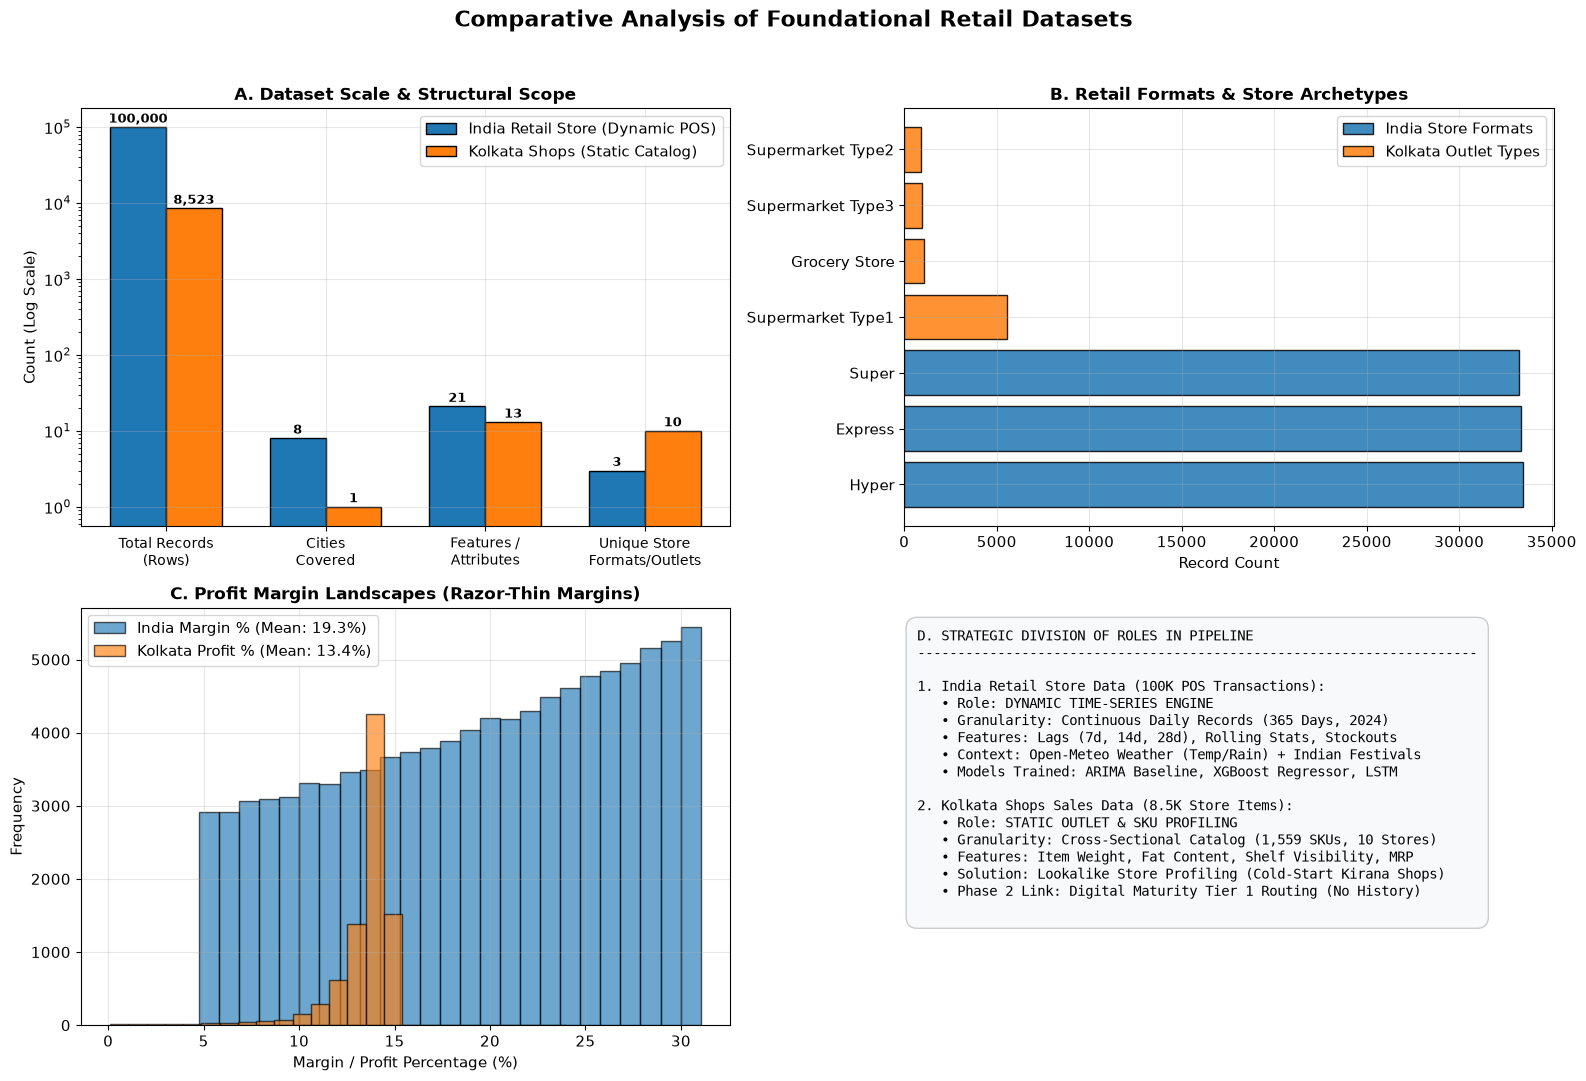

In [96]:
# Cell 3: Presentation Graphic - Comparative Architecture of Both Datasets
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Dataset Scale & Scope Comparison
metrics = ['Total Records\n(Rows)', 'Cities\nCovered', 'Features /\nAttributes', 'Unique Store\nFormats/Outlets']
india_vals = [len(india_df), india_df['City'].nunique(), len(india_df.columns), india_df['Store_Format'].nunique()]
kolkata_vals = [len(kolkata_df), 1, len(kolkata_df.columns), kolkata_df['Outlet_Identifier'].nunique()]

x = np.arange(len(metrics))
width = 0.35
axes[0, 0].bar(x - width/2, india_vals, width, label='India Retail Store (Dynamic POS)', color='#1f77b4', edgecolor='black')
axes[0, 0].bar(x + width/2, kolkata_vals, width, label='Kolkata Shops (Static Catalog)', color='#ff7f0e', edgecolor='black')
axes[0, 0].set_yscale('log')
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(metrics, fontsize=10)
axes[0, 0].set_ylabel('Count (Log Scale)')
axes[0, 0].set_title('A. Dataset Scale & Structural Scope', fontweight='bold', fontsize=12)
axes[0, 0].legend()
for i in range(len(metrics)):
    axes[0, 0].text(x[i] - width/2, india_vals[i]*1.15, f'{india_vals[i]:,}', ha='center', fontsize=9, fontweight='bold')
    axes[0, 0].text(x[i] + width/2, kolkata_vals[i]*1.15, f'{kolkata_vals[i]:,}', ha='center', fontsize=9, fontweight='bold')

# 2. Store Formats & Retail Archetypes
format_counts = india_df['Store_Format'].value_counts()
outlet_counts = kolkata_df['Outlet_Type'].value_counts()
axes[0, 1].barh(format_counts.index, format_counts.values, color='#1f77b4', alpha=0.85, edgecolor='black', label='India Store Formats')
axes[0, 1].barh(outlet_counts.index, outlet_counts.values, color='#ff7f0e', alpha=0.85, edgecolor='black', label='Kolkata Outlet Types')
axes[0, 1].set_title('B. Retail Formats & Store Archetypes', fontweight='bold', fontsize=12)
axes[0, 1].set_xlabel('Record Count')
axes[0, 1].legend()

# 3. Profit Margin Distributions (The Thin-Margin Dilemma)
axes[1, 0].hist(india_df['Margin_%'] * 100, bins=25, alpha=0.65, color='#1f77b4', edgecolor='black', label=f'India Margin % (Mean: {india_df["Margin_%"].mean()*100:.1f}%)')
axes[1, 0].hist(kolkata_df['Profit'], bins=25, alpha=0.65, color='#ff7f0e', edgecolor='black', label=f'Kolkata Profit % (Mean: {kolkata_df["Profit"].mean():.1f}%)')
axes[1, 0].set_title('C. Profit Margin Landscapes (Razor-Thin Margins)', fontweight='bold', fontsize=12)
axes[1, 0].set_xlabel('Margin / Profit Percentage (%)')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].legend()

# 4. Strategic Division of Roles in Architecture
axes[1, 1].axis('off')
role_text = (
    'D. STRATEGIC DIVISION OF ROLES IN PIPELINE\n'
    '----------------------------------------------------------------------\n\n'
    '1. India Retail Store Data (100K POS Transactions):\n'
    '   • Role: DYNAMIC TIME-SERIES ENGINE\n'
    '   • Granularity: Continuous Daily Records (365 Days, 2024)\n'
    '   • Features: Lags (7d, 14d, 28d), Rolling Stats, Stockouts\n'
    '   • Context: Open-Meteo Weather (Temp/Rain) + Indian Festivals\n'
    '   • Models Trained: ARIMA Baseline, XGBoost Regressor, LSTM\n\n'
    '2. Kolkata Shops Sales Data (8.5K Store Items):\n'
    '   • Role: STATIC OUTLET & SKU PROFILING\n'
    '   • Granularity: Cross-Sectional Catalog (1,559 SKUs, 10 Stores)\n'
    '   • Features: Item Weight, Fat Content, Shelf Visibility, MRP\n'
    '   • Solution: Lookalike Store Profiling (Cold-Start Kirana Shops)\n'
    '   • Phase 2 Link: Digital Maturity Tier 1 Routing (No History)\n'
)
axes[1, 1].text(0.02, 0.95, role_text, transform=axes[1, 1].transAxes, fontsize=10, verticalalignment='top',
                fontfamily='monospace', bbox=dict(boxstyle='round,pad=0.8', facecolor='#f8f9fa', edgecolor='#cccccc'))

plt.suptitle('Comparative Analysis of Foundational Retail Datasets', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(os.path.join(OUTPUTS_DIR, 'presentation_dataset_comparison.png'), dpi=200)
plt.show()

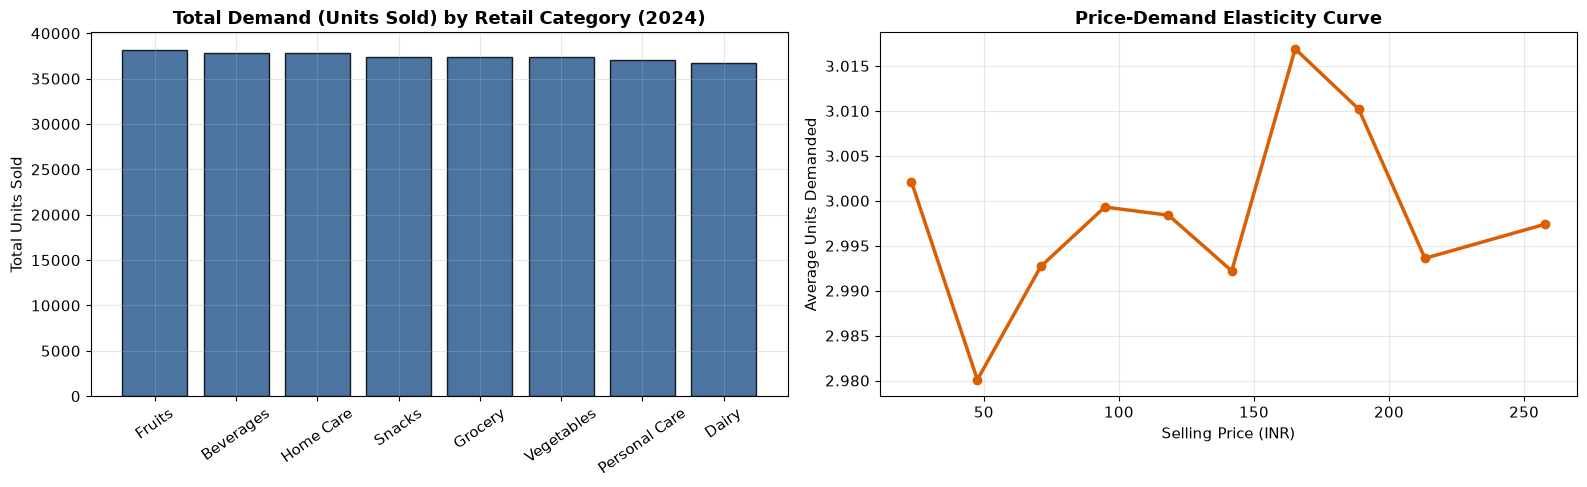

In [97]:
# Cell 4: Demand Distribution & Price Elasticity Curve
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Total Volume by Retail Category
cat_volume = india_df.groupby('Category')['Units'].sum().sort_values(ascending=False)
axes[0].bar(cat_volume.index, cat_volume.values, color='#2b5c8f', edgecolor='black', alpha=0.85)
axes[0].set_title('Total Demand (Units Sold) by Retail Category (2024)', fontweight='bold')
axes[0].set_ylabel('Total Units Sold')
axes[0].tick_params(axis='x', rotation=35)

# 2. Price Elasticity Curve (Matching PDF Slide 3)
price_bins = pd.qcut(india_df['Selling_Price'], q=10)
elasticity = india_df.groupby(price_bins)['Units'].mean()
bin_centers = [interval.mid for interval in elasticity.index]

axes[1].plot(bin_centers, elasticity.values, marker='o', linewidth=2.5, color='#d95f02')
axes[1].set_title('Price-Demand Elasticity Curve', fontweight='bold')
axes[1].set_xlabel('Selling Price (INR)')
axes[1].set_ylabel('Average Units Demanded')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, 'eda_category_and_elasticity.png'), dpi=150)
plt.show()

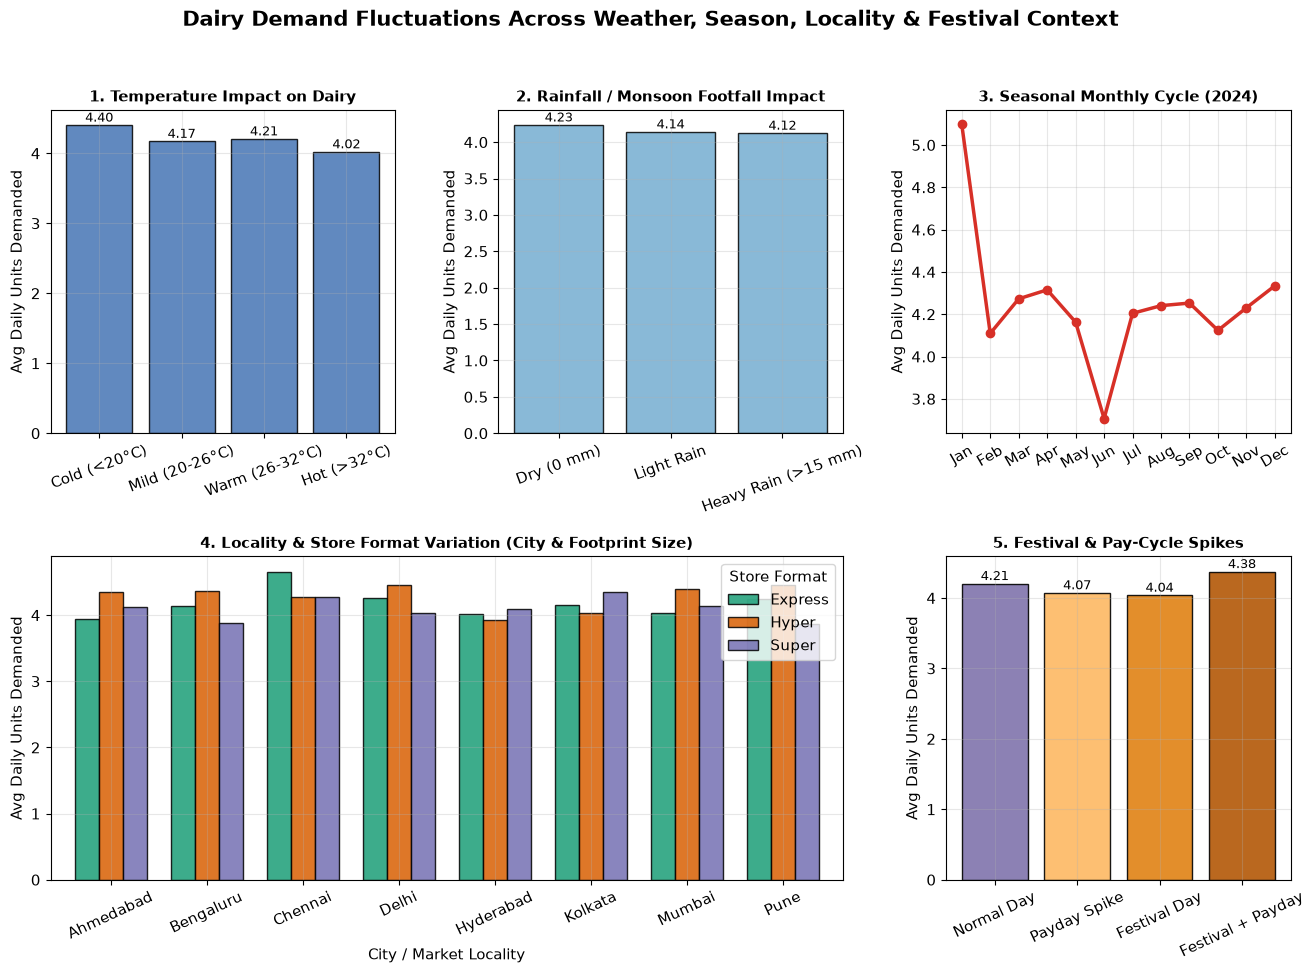

SUCCESS: Saved high-resolution graphic to -> outputs/dairy_contextual_fluctuations.png


In [98]:
# ==============================================================================
# Cell: Contextual Demand Fluctuations for Dairy (Weather, Seasons, Locality, Festivals)
# ==============================================================================
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Load the feature-engineered dataset
datasets_dir = 'datasets' if os.path.exists('datasets') else '.'
outputs_dir = 'outputs' if os.path.exists('outputs') else '.'
df = pd.read_csv(os.path.join(datasets_dir, 'xgb_training_ready.csv'))

# Filter specifically for the Dairy product department
dairy = df[df['Category'] == 'Dairy'].copy()
dairy['Date'] = pd.to_datetime(dairy['Date'])

# Create a multi-panel dashboard
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 3, hspace=0.38, wspace=0.3)

# ------------------------------------------------------------------------------
# 1. Temperature Impact (Cold vs. Mild vs. Hot Days)
# ------------------------------------------------------------------------------
ax1 = fig.add_subplot(gs[0, 0])
temp_bins = pd.cut(
    dairy['Avg_Temperature_C'],
    bins=[0, 20, 26, 32, 45],
    labels=['Cold (<20°C)', 'Mild (20-26°C)', 'Warm (26-32°C)', 'Hot (>32°C)'],
)
temp_grp = dairy.groupby(temp_bins)['Total_Units'].mean()
bars1 = ax1.bar(
    temp_grp.index.astype(str),
    temp_grp.values,
    color='#4575b4',
    edgecolor='black',
    alpha=0.85,
)
ax1.set_title('1. Temperature Impact on Dairy', fontweight='bold', fontsize=11)
ax1.set_ylabel('Avg Daily Units Demanded')
ax1.tick_params(axis='x', rotation=20)
for bar in bars1:
  ax1.text(
      bar.get_x() + bar.get_width() / 2,
      bar.get_height() + 0.05,
      f'{bar.get_height():.2f}',
      ha='center',
      fontsize=9,
  )

# ------------------------------------------------------------------------------
# 2. Rainfall / Monsoon Impact
# ------------------------------------------------------------------------------
ax2 = fig.add_subplot(gs[0, 1])
rain_bins = pd.cut(
    dairy['Precipitation_mm'],
    bins=[-1, 0.1, 15, 200],
    labels=['Dry (0 mm)', 'Light Rain', 'Heavy Rain (>15 mm)'],
)
rain_grp = dairy.groupby(rain_bins)['Total_Units'].mean()
bars2 = ax2.bar(
    rain_grp.index.astype(str),
    rain_grp.values,
    color='#74add1',
    edgecolor='black',
    alpha=0.85,
)
ax2.set_title(
    '2. Rainfall / Monsoon Footfall Impact', fontweight='bold', fontsize=11
)
ax2.set_ylabel('Avg Daily Units Demanded')
ax2.tick_params(axis='x', rotation=20)
for bar in bars2:
  ax2.text(
      bar.get_x() + bar.get_width() / 2,
      bar.get_height() + 0.05,
      f'{bar.get_height():.2f}',
      ha='center',
      fontsize=9,
  )

# ------------------------------------------------------------------------------
# 3. Seasonal Progression (Month-by-Month Trend across 2024)
# ------------------------------------------------------------------------------
ax3 = fig.add_subplot(gs[0, 2])
monthly_dairy = dairy.groupby('Month')['Total_Units'].mean()
months = [
    'Jan',
    'Feb',
    'Mar',
    'Apr',
    'May',
    'Jun',
    'Jul',
    'Aug',
    'Sep',
    'Oct',
    'Nov',
    'Dec',
]
ax3.plot(
    months,
    monthly_dairy.values,
    marker='o',
    color='#d73027',
    linewidth=2.5,
    markersize=6,
)
ax3.set_title(
    '3. Seasonal Monthly Cycle (2024)', fontweight='bold', fontsize=11
)
ax3.set_ylabel('Avg Daily Units Demanded')
ax3.tick_params(axis='x', rotation=30)
ax3.grid(True, alpha=0.3)

# ------------------------------------------------------------------------------
# 4. Area / Locality & Store Format Variations (Kirana Express vs. Super vs. Hyper)
# ------------------------------------------------------------------------------
ax4 = fig.add_subplot(gs[1, :2])
city_format = (
    dairy.groupby(['City', 'Store_Format'])['Total_Units'].mean().unstack()
)
city_format.plot(
    kind='bar',
    ax=ax4,
    color=['#1b9e77', '#d95f02', '#7570b3'],
    edgecolor='black',
    alpha=0.85,
    width=0.75,
)
ax4.set_title(
    '4. Locality & Store Format Variation (City & Footprint Size)',
    fontweight='bold',
    fontsize=11,
)
ax4.set_ylabel('Avg Daily Units Demanded')
ax4.set_xlabel('City / Market Locality')
ax4.legend(title='Store Format')
ax4.tick_params(axis='x', rotation=25)

# ------------------------------------------------------------------------------
# 5. Festival & Pay-Cycle Uplift
# ------------------------------------------------------------------------------
ax5 = fig.add_subplot(gs[1, 2])


def categorize_event(row):
  if row['Is_Holiday'] == 1 and row['Is_Payday'] == 1:
    return 'Festival + Payday'
  elif row['Is_Holiday'] == 1:
    return 'Festival Day'
  elif row['Is_Payday'] == 1:
    return 'Payday Spike'
  else:
    return 'Normal Day'


dairy['Event_Type'] = dairy.apply(categorize_event, axis=1)
event_order = [
    'Normal Day',
    'Payday Spike',
    'Festival Day',
    'Festival + Payday',
]
event_grp = (
    dairy.groupby('Event_Type')['Total_Units'].mean().reindex(event_order)
)

bars5 = ax5.bar(
    event_grp.index,
    event_grp.values,
    color=['#8073ac', '#fdb863', '#e08214', '#b35806'],
    edgecolor='black',
    alpha=0.9,
)
ax5.set_title(
    '5. Festival & Pay-Cycle Spikes', fontweight='bold', fontsize=11
)
ax5.set_ylabel('Avg Daily Units Demanded')
ax5.tick_params(axis='x', rotation=25)
for bar in bars5:
  ax5.text(
      bar.get_x() + bar.get_width() / 2,
      bar.get_height() + 0.05,
      f'{bar.get_height():.2f}',
      ha='center',
      fontsize=9,
  )

plt.suptitle(
    'Dairy Demand Fluctuations Across Weather, Season, Locality & Festival'
    ' Context',
    fontsize=15,
    fontweight='bold',
    y=0.98,
)
plt.savefig(
    os.path.join(outputs_dir, 'dairy_contextual_fluctuations.png'),
    dpi=200,
    bbox_inches='tight',
)
plt.show()
print(
    'SUCCESS: Saved high-resolution graphic to ->'
    f" {os.path.join(outputs_dir, 'dairy_contextual_fluctuations.png')}"
)

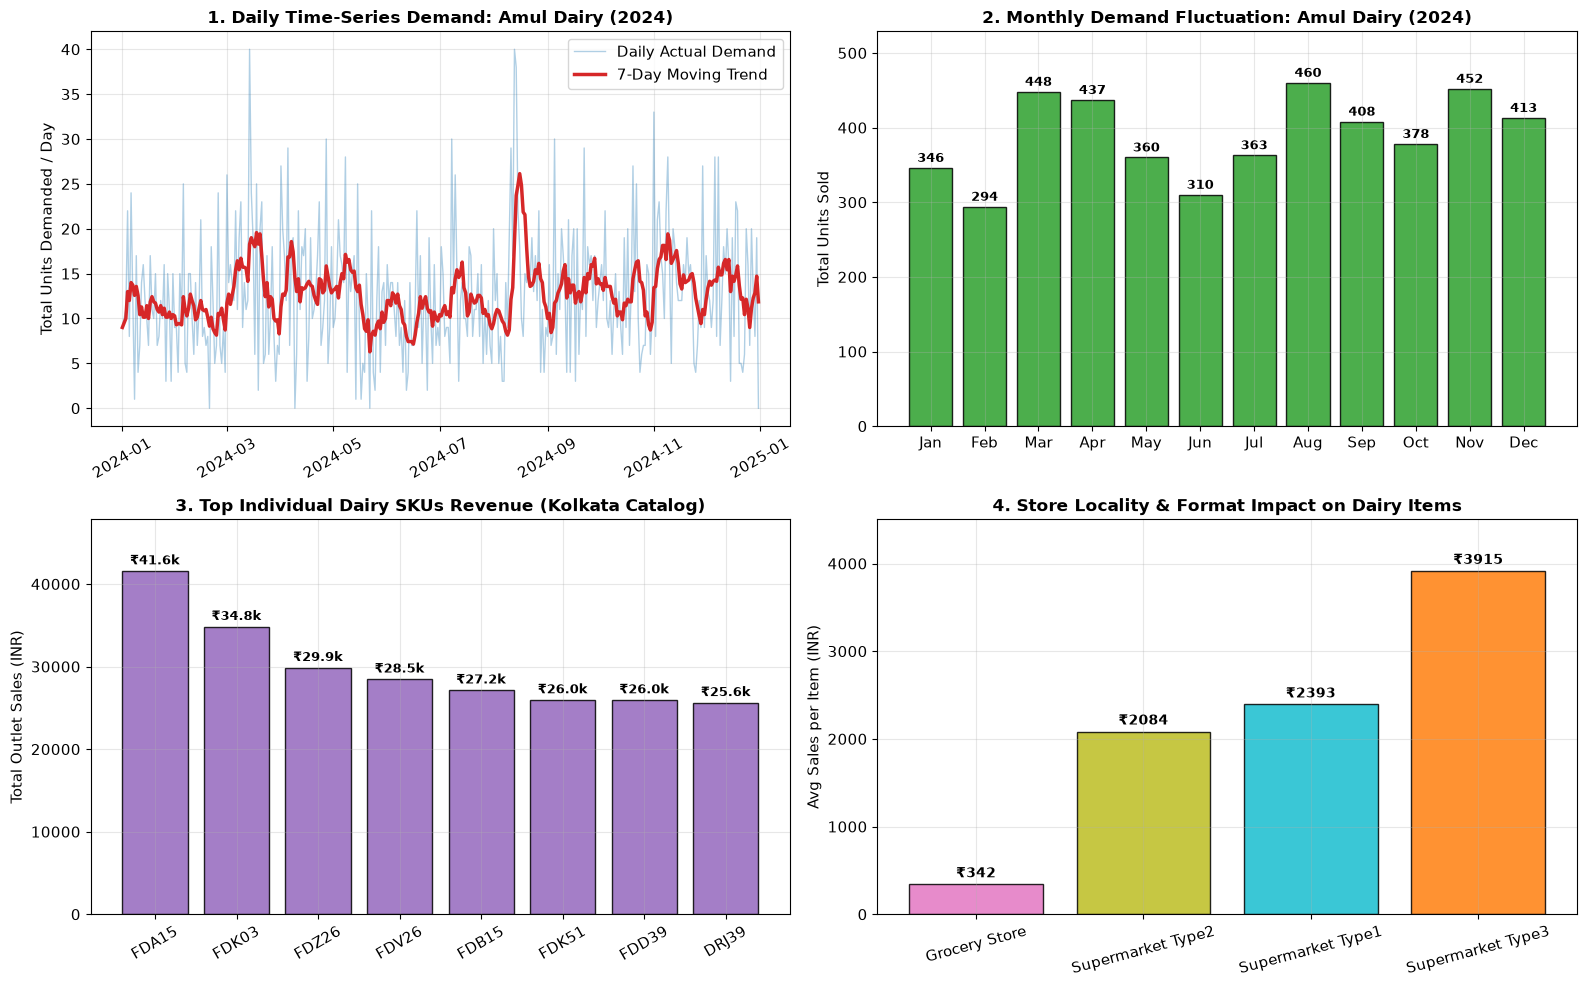

In [99]:
# Cell: Granular Demand Fluctuations for Specific Dairy Items & Brands
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Filter for a specific Dairy Brand: Amul (Time-Series POS Data)
amul_df = india_df[(india_df['Category'] == 'Dairy') & (india_df['Brand'] == 'Amul')].copy()
amul_df['Date'] = pd.to_datetime(amul_df['Invoice_Date']).dt.date
amul_df['Month'] = pd.to_datetime(amul_df['Invoice_Date']).dt.strftime('%b')

# Reindex across all 365 days of 2024 to capture day-to-day fluctuations
daily_amul = amul_df.groupby('Date')['Units'].sum()
all_dates = pd.date_range(start='2024-01-01', end='2024-12-31')
daily_amul = daily_amul.reindex(all_dates.date, fill_value=0)

# 2. Filter for individual Dairy SKUs (Kolkata Outlet Catalog)
kolkata_dairy = kolkata_df[kolkata_df['Item_Type'] == 'Dairy'].copy()
top_skus = kolkata_dairy.groupby('Item_Identifier')['Item_Outlet_Sales'].sum().sort_values(ascending=False).head(8)

# 3. Create 4-panel granular visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Panel 1: Day-to-Day Time-Series Volatility (Amul Dairy)
axes[0, 0].plot(daily_amul.index, daily_amul.values, color='#1f77b4', alpha=0.35, linewidth=1, label='Daily Actual Demand')
axes[0, 0].plot(daily_amul.index, daily_amul.rolling(7, min_periods=1).mean(), color='#d62728', linewidth=2.5, label='7-Day Moving Trend')
axes[0, 0].set_title('1. Daily Time-Series Demand: Amul Dairy (2024)', fontweight='bold', fontsize=12)
axes[0, 0].set_ylabel('Total Units Demanded / Day')
axes[0, 0].legend(loc='upper right')
axes[0, 0].tick_params(axis='x', rotation=30)

# Panel 2: Monthly Seasonal Cyclicality (Amul Dairy)
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_amul = amul_df.groupby('Month')['Units'].sum().reindex(month_order)
bars2 = axes[0, 1].bar(monthly_amul.index, monthly_amul.values, color='#2ca02c', edgecolor='black', alpha=0.85)
for bar in bars2:
    y = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2, y + 8, f'{int(y)}', ha='center', fontsize=9, fontweight='bold')
axes[0, 1].set_ylim(0, monthly_amul.max() * 1.15)
axes[0, 1].set_title('2. Monthly Demand Fluctuation: Amul Dairy (2024)', fontweight='bold', fontsize=12)
axes[0, 1].set_ylabel('Total Units Sold')

# Panel 3: Individual Dairy SKU Revenue Variance (Kolkata Outlets)
bars3 = axes[1, 0].bar(top_skus.index, top_skus.values, color='#9467bd', edgecolor='black', alpha=0.85)
for bar in bars3:
    y = bar.get_height()
    axes[1, 0].text(bar.get_x() + bar.get_width()/2, y + 800, f'₹{y/1000:.1f}k', ha='center', fontsize=9, fontweight='bold')
axes[1, 0].set_ylim(0, top_skus.max() * 1.15)
axes[1, 0].set_title('3. Top Individual Dairy SKUs Revenue (Kolkata Catalog)', fontweight='bold', fontsize=12)
axes[1, 0].set_ylabel('Total Outlet Sales (INR)')
axes[1, 0].tick_params(axis='x', rotation=30)

# Panel 4: Store Format & Locality Disparity on Dairy Items
outlet_sales = kolkata_dairy.groupby('Outlet_Type')['Item_Outlet_Sales'].mean().sort_values()
palette = ['#e377c2', '#bcbd22', '#17becf', '#ff7f0e']
bars4 = axes[1, 1].bar(outlet_sales.index, outlet_sales.values, color=palette, edgecolor='black', alpha=0.85)
for bar in bars4:
    y = bar.get_height()
    axes[1, 1].text(bar.get_x() + bar.get_width()/2, y + 80, f'₹{y:.0f}', ha='center', fontsize=10, fontweight='bold')
axes[1, 1].set_ylim(0, outlet_sales.max() * 1.15)
axes[1, 1].set_title('4. Store Locality & Format Impact on Dairy Items', fontweight='bold', fontsize=12)
axes[1, 1].set_ylabel('Avg Sales per Item (INR)')
axes[1, 1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, 'dairy_granular_fluctuations.png'), dpi=150)
plt.show()

---
## Step 2: Contextual External Signals (Weather & Festivals)

As outlined in **Slide 5 of the project proposal**, demand cannot be predicted from internal POS logs alone. External factors dictate shopping behavior:
1. **Weather Context**: Heatwaves trigger cold beverage spikes; heavy monsoon rains suppress footfall.
2. **Festival Context**: Durga Puja and Diwali cause massive grocery and dairy demand surges.
3. **Payday Cycle**: Month-start and month-end paydays (1st, 30th, 31st) cause bulk grocery buying.

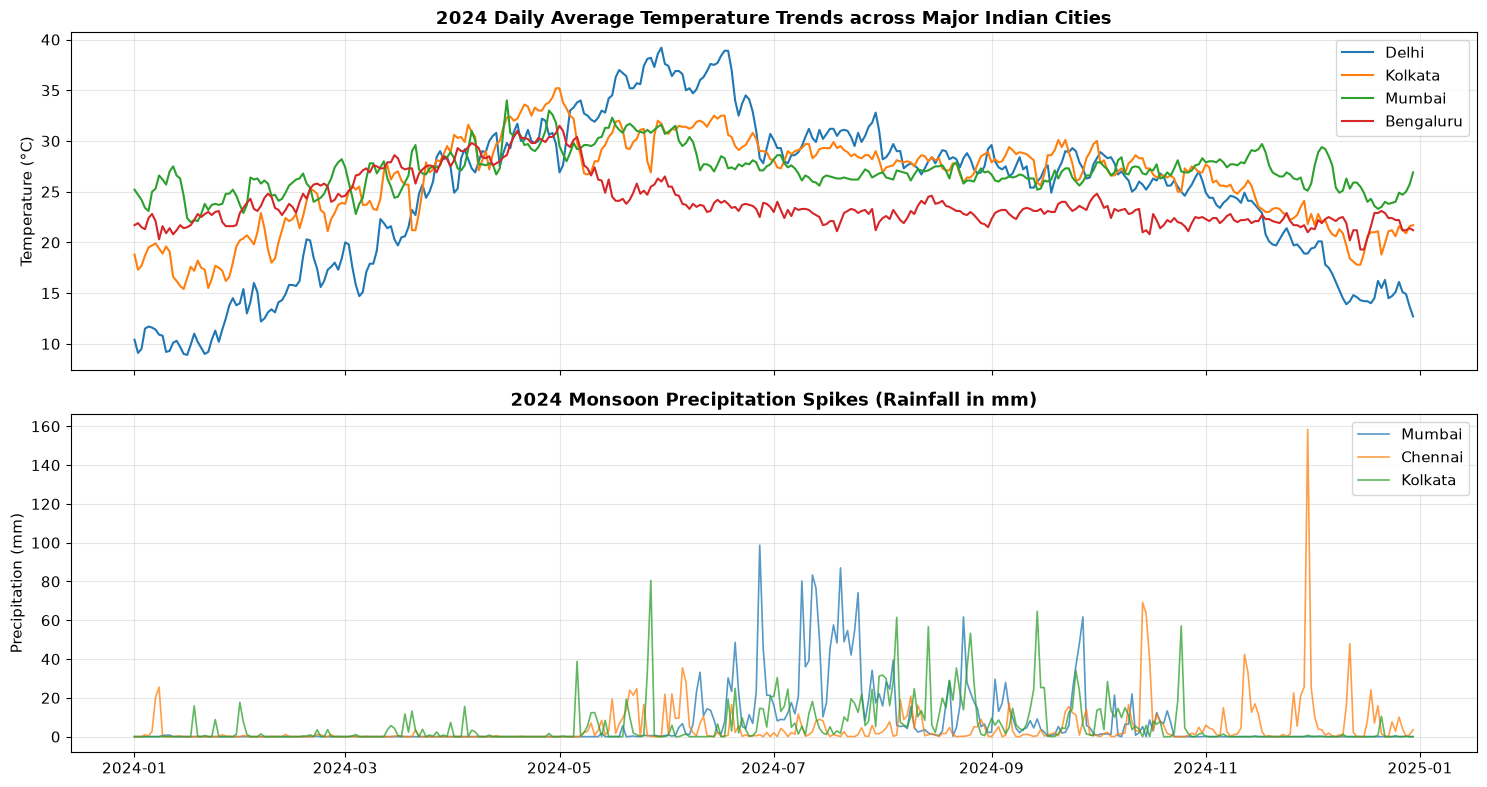

In [100]:
# Cell 5: Load and Visualize Real 2024 Weather Data (Open-Meteo ERA5)
weather_df = pd.read_csv(os.path.join(DATASETS_DIR, 'historical_weather_2024.csv'))
weather_df['Date'] = pd.to_datetime(weather_df['Date'])

fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

# Temperature Trends across Cities
for city in ['Delhi', 'Kolkata', 'Mumbai', 'Bengaluru']:
    city_w = weather_df[weather_df['City'] == city].sort_values('Date')
    axes[0].plot(city_w['Date'], city_w['Avg_Temperature_C'], label=city, linewidth=1.5)
axes[0].set_title('2024 Daily Average Temperature Trends across Major Indian Cities', fontweight='bold')
axes[0].set_ylabel('Temperature (°C)')
axes[0].legend(loc='upper right')

# Monsoon Rainfall Spikes
for city in ['Mumbai', 'Chennai', 'Kolkata']:
    city_w = weather_df[weather_df['City'] == city].sort_values('Date')
    axes[1].plot(city_w['Date'], city_w['Precipitation_mm'], label=city, alpha=0.75, linewidth=1.2)
axes[1].set_title('2024 Monsoon Precipitation Spikes (Rainfall in mm)', fontweight='bold')
axes[1].set_ylabel('Precipitation (mm)')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, 'weather_context_trends.png'), dpi=150)
plt.show()

---
## Step 3: Mitigating Retail Flaws & Feature Engineering

### 1. Censored Demand (Stockout Recovery)
When inventory drops below safety levels (`Stock_On_Hand <= Reorder_Level`), customers cannot purchase items. Observed sales drop to 0, which tricks a naive ML model into believing demand dropped!  
We use conditional expectation imputation to recover the unconstrained latent demand:
$$\hat{D} = \max\left(Y_{\text{obs}}, \mathbb{E}[D \mid \text{City}, \text{Format}, \text{Category}, \text{DayOfWeek}]\right)$$

### 2. Zero-Inflated Smoothing & Full Date Grid
Retail transactions skip days when sales are 0. We construct a complete Cartesian grid ($365 \text{ days} \times 8 \text{ cities} \times 3 \text{ formats} \times 8 \text{ categories}$) to record true zeros, and aggregate weekly to smooth sparsity.

In [101]:
# Cell 6: Run Feature Engineering & Retail Flaw Mitigation Pipeline
from preprocess_india_retail_store_data import preprocess_all

# Ensure feature engineering pipeline is executed and up to date
if not os.path.exists(os.path.join(DATASETS_DIR, 'xgb_training_ready.csv')):
    print("[Info] Running end-to-end feature engineering pipeline...")
    preprocess_all(datasets_dir=DATASETS_DIR)

train_ready_df = pd.read_csv(os.path.join(DATASETS_DIR, 'xgb_training_ready.csv'))
train_ready_df['Date'] = pd.to_datetime(train_ready_df['Date'])

print(f"Enriched Feature Dataset: {train_ready_df.shape[0]:,} rows, {train_ready_df.shape[1]} features")
print(f"Censored Stockout Days Recovered: {train_ready_df['Is_Stockout_Censored'].sum():,} records")

# Display engineered columns
print("\nEngineered Feature Set:")
for i, col in enumerate(train_ready_df.columns, 1):
    print(f" {i:2d}. {col}")

Enriched Feature Dataset: 64,704 rows, 25 features
Censored Stockout Days Recovered: 583 records

Engineered Feature Set:
  1. Date
  2. City
  3. Store_Format
  4. Category
  5. Total_Units
  6. Avg_Selling_Price
  7. Stock_On_Hand
  8. Reorder_Level
  9. Day_of_Week
 10. Month
 11. Day
 12. Is_Weekend
 13. Is_Payday
 14. Is_Holiday
 15. Avg_Temperature_C
 16. Precipitation_mm
 17. Expected_Uncensored_Units
 18. Is_Stockout_Censored
 19. Imputed_Demand
 20. Units_Lag_7d
 21. Units_Lag_14d
 22. Units_Lag_28d
 23. Units_Rolling_Mean_7d
 24. Units_Rolling_Mean_14d
 25. Units_Rolling_Std_7d


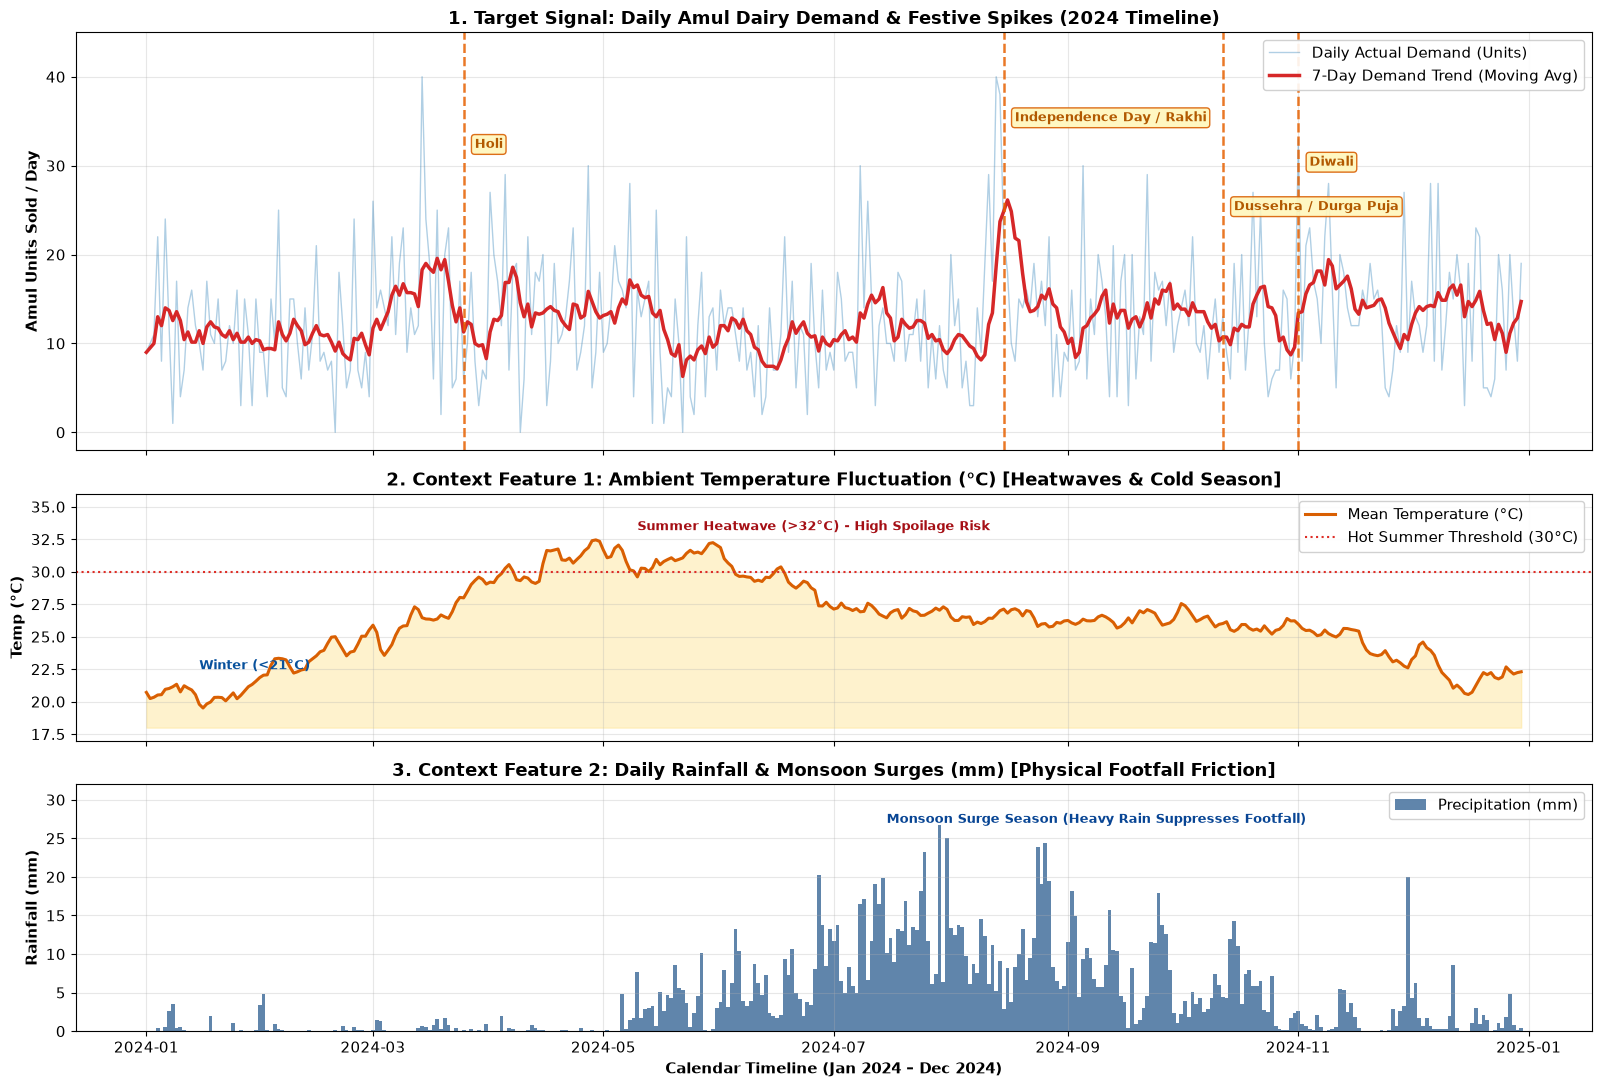

In [102]:
# Cell: Multi-Feature Contextual Timeline (Demand vs Temperature, Monsoon & Festivals)
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Filter Amul Dairy Daily Demand
amul_df = india_df[(india_df['Category'] == 'Dairy') & (india_df['Brand'] == 'Amul')].copy()
amul_df['Date'] = pd.to_datetime(amul_df['Invoice_Date']).dt.date
daily_amul = amul_df.groupby('Date')['Units'].sum()

# Align across the full 2024 calendar year
all_dates = pd.date_range(start='2024-01-01', end='2024-12-30')
daily_amul = daily_amul.reindex(all_dates.date, fill_value=0)

# 2. Daily Contextual Weather (Open-Meteo ERA5 2024)
weather_df = pd.read_csv(os.path.join(DATASETS_DIR, 'historical_weather_2024.csv'))
weather_df['Date_dt'] = pd.to_datetime(weather_df['Date']).dt.date
daily_weather = weather_df.groupby('Date_dt')[['Avg_Temperature_C', 'Precipitation_mm']].mean().reindex(all_dates.date)

# 3. Key Indian Retail Festivals
festivals = [
    ('2024-03-25', 'Holi', 32),
    ('2024-08-15', 'Independence Day / Rakhi', 35),
    ('2024-10-12', 'Dussehra / Durga Puja', 25),
    ('2024-11-01', 'Diwali', 30),
]

# 4. Construct Aligned 3-Tier Figure with Shared X-Axis
fig, axes = plt.subplots(3, 1, figsize=(16, 11), sharex=True, gridspec_kw={'height_ratios': [2.2, 1.3, 1.3]})

# --- Panel 1: Target Demand & Festival Surges ---
axes[0].plot(all_dates, daily_amul.values, color='#1f77b4', alpha=0.35, linewidth=1, label='Daily Actual Demand (Units)')
rolling_7d = pd.Series(daily_amul.values).rolling(7, min_periods=1).mean()
axes[0].plot(all_dates, rolling_7d, color='#d62728', linewidth=2.5, label='7-Day Demand Trend (Moving Avg)')

for f_date, f_name, y_pos in festivals:
    dt = pd.to_datetime(f_date)
    axes[0].axvline(dt, color='#e66101', linestyle='--', linewidth=1.8, alpha=0.85)
    axes[0].annotate(
        f_name, 
        xy=(dt, y_pos), 
        xytext=(8, 0), 
        textcoords='offset points',
        fontsize=9.5, 
        fontweight='bold', 
        color='#b25900',
        bbox=dict(boxstyle='round,pad=0.25', facecolor='#fff7bc', edgecolor='#d95f02', alpha=0.9)
    )

axes[0].set_title('1. Target Signal: Daily Amul Dairy Demand & Festive Spikes (2024 Timeline)', fontweight='bold', fontsize=13)
axes[0].set_ylabel('Amul Units Sold / Day', fontweight='bold')
axes[0].set_ylim(-2, 45)
axes[0].legend(loc='upper right', framealpha=0.9)
axes[0].grid(True, alpha=0.3)

# --- Panel 2: Context Feature 1 - Temperature ---
axes[1].plot(all_dates, daily_weather['Avg_Temperature_C'], color='#d95f02', linewidth=2.2, label='Mean Temperature (°C)')
axes[1].fill_between(all_dates, daily_weather['Avg_Temperature_C'], 18, color='#fee391', alpha=0.45)
axes[1].axhline(30, color='#de2d26', linestyle=':', linewidth=1.5, label='Hot Summer Threshold (30°C)')
axes[1].set_title('2. Context Feature 1: Ambient Temperature Fluctuation (°C) [Heatwaves & Cold Season]', fontweight='bold', fontsize=13)
axes[1].set_ylabel('Temp (°C)', fontweight='bold')
axes[1].set_ylim(17, 36)
axes[1].text(pd.to_datetime('2024-05-10'), 33.2, 'Summer Heatwave (>32°C) - High Spoilage Risk', color='#a50f15', fontsize=9.5, fontweight='bold')
axes[1].text(pd.to_datetime('2024-01-15'), 22.5, 'Winter (<21°C)', color='#08519c', fontsize=9.5, fontweight='bold')
axes[1].legend(loc='upper right', framealpha=0.9)
axes[1].grid(True, alpha=0.3)

# --- Panel 3: Context Feature 2 - Rainfall / Monsoon ---
axes[2].bar(all_dates, daily_weather['Precipitation_mm'], color='#2b5c8f', width=1.0, alpha=0.75, label='Precipitation (mm)')
axes[2].set_title('3. Context Feature 2: Daily Rainfall & Monsoon Surges (mm) [Physical Footfall Friction]', fontweight='bold', fontsize=13)
axes[2].set_ylabel('Rainfall (mm)', fontweight='bold')
axes[2].set_xlabel('Calendar Timeline (Jan 2024 – Dec 2024)', fontweight='bold')
axes[2].set_ylim(0, 32)
axes[2].text(pd.to_datetime('2024-07-15'), 27, 'Monsoon Surge Season (Heavy Rain Suppresses Footfall)', color='#084594', fontsize=9.5, fontweight='bold')
axes[2].legend(loc='upper right', framealpha=0.9)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, 'dairy_weather_festivals_timeline.png'), dpi=150)
plt.show()

---
## Step 4: Dataset Engineering & Contextual Exploration Complete

All foundational retail datasets, external weather signals, and holiday/payday contextual features have been engineered and saved to `datasets/`:
* `india_retail_store.csv` & `kolkata_data.csv` (Raw Ingestion)
* `historical_weather_2024.csv` (Open-Meteo ERA5 2024)
* `xgb_training_ready.csv` (Daily Feature-Engineered Dataset with Lags & Rolling Stats)
* `weekly_demand_training_ready.csv` (Weekly Aggregated Dataset)
* `outlet_lookalike_profiles.csv` (Kolkata Outlet Catalog & Profiling)

**Next Step**: Open **`Comparative_Model_Benchmarking.ipynb`** to train and benchmark all 6 models (ARIMA, Random Forest, LightGBM, CatBoost, XGBoost, and LSTM), validate against Concept Drift across seasonal windows, and simulate Business KPIs (Holding Cost, Spoilage, Stockouts).

---
## Step 4: Dataset Engineering & Contextual Exploration Complete

All foundational retail datasets, external weather signals, and holiday/payday contextual features have been engineered and saved to `datasets/`:
* `india_retail_store.csv` & `kolkata_data.csv` (Raw Ingestion)
* `historical_weather_2024.csv` (Open-Meteo ERA5 2024)
* `xgb_training_ready.csv` (Daily Feature-Engineered Dataset with Lags & Rolling Stats)
* `weekly_demand_training_ready.csv` (Weekly Aggregated Dataset)
* `outlet_lookalike_profiles.csv` (Kolkata Outlet Catalog & Profiling)

**Next Step**: Open **`Comparative_Model_Benchmarking.ipynb`** to train and benchmark all 6 models (ARIMA, Random Forest, LightGBM, CatBoost, XGBoost, and LSTM), validate against Concept Drift across seasonal windows, and simulate Business KPIs (Holding Cost, Spoilage, Stockouts).